In [1]:
#imports
import matplotlib.pyplot as plt
import numpy as np
import pickle

import copy
from pathlib import Path


import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

# Set random seeds for reproducibility (same as Exercise 2)
np.random.seed(42)
torch.manual_seed(42)

print("PyTorch Version:", torch.__version__)

PyTorch Version: 2.14.1+cu130


In [2]:
#load the data file
with open("delta_data.pkl", "rb") as file:
    delta_data = pickle.load(file)

In [3]:
def deltas_to_strokes(trajectory):
    """
    Reconstructs (x, y) strokes from (dx, dy, pen_state).

    pen_state = 0: pen is DOWN (this step is part of a stroke -> draw it)
    pen_state = 1: pen is UP   (this step is an air move -> skip it)
    pen_state = 2: END         (stop before applying this step)
    """
    strokes = []
    current_stroke = []

    x, y = 0.0, 0.0

    for dx, dy, pen_state in trajectory:
        if pen_state == 2:
            break

        prev_x, prev_y = x, y
        x = x + dx
        y = y + dy

        if pen_state == 0:
            # Pen is DOWN: include this step in the current stroke
            if not current_stroke:
                # First point of the stroke: include the "from" position too
                current_stroke.append((prev_x, prev_y))
            current_stroke.append((x, y))

        else:
            # Pen is UP: flying through the air
            # Save the stroke we were drawing (if any) and reset
            if current_stroke:
                strokes.append(current_stroke)
                current_stroke = []

    # Save the last stroke if it exists
    if current_stroke:
        strokes.append(current_stroke)
    return strokes




Character 'a' has 1 strokes after reconstruction.
Character 'b' has 1 strokes after reconstruction.
Character 'c' has 1 strokes after reconstruction.
Character 'A' has 2 strokes after reconstruction.
Character 'B' has 1 strokes after reconstruction.
Character 'C' has 1 strokes after reconstruction.
Character '1' has 1 strokes after reconstruction.
Character '2' has 1 strokes after reconstruction.
Character '3' has 1 strokes after reconstruction.


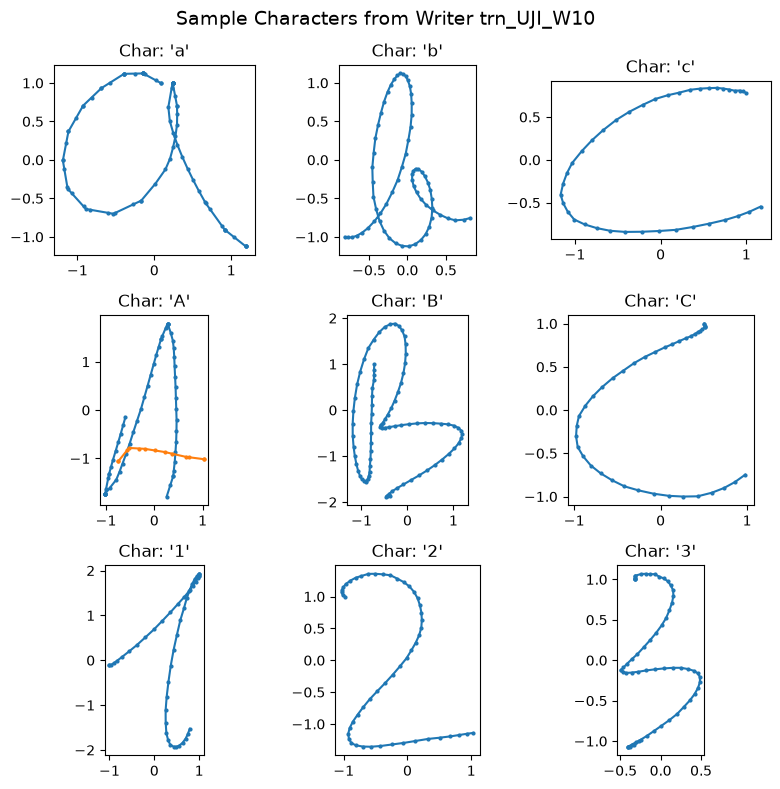

In [4]:
# Plot from delta_data
characters = ['a', 'b', 'c', 'A', 'B', 'C', '1', '2', '3']
writer = "trn_UJI_W10"

fig, axes = plt.subplots(3, 3, figsize=(8, 8))

for ax, char in zip(axes.flat, characters):
    # Get the flat trajectory from delta_data
    trajectory = delta_data[writer][char][0]

    # Reconstruct strokes from (dx, dy, pen_state)
    strokes = deltas_to_strokes(trajectory)
    print(f"Character '{char}' has {len(strokes)} strokes after reconstruction.")

    for stroke in strokes:
        xs = [p[0] for p in stroke]
        ys = [p[1] for p in stroke]
        ax.plot(xs, ys, "-o", markersize=2)

    ax.set_aspect("equal")
    ax.set_title(f"Char: '{char}'")

plt.suptitle(f"Sample Characters from Writer {writer}", fontsize=14)
plt.tight_layout()
plt.show()

In [5]:
train_data = {}
val_data = {}
test_data = {}

# 1. Collect all test writer IDs
test_writer_ids = []
for writer_id in delta_data:
    if writer_id.startswith("tst_"):
        test_writer_ids.append(writer_id)

test_writer_ids.sort()

# 2. Split the 20 test writers in half (10 for val, 10 for test)
val_writers = test_writer_ids[:10]
test_writers = test_writer_ids[10:]

# 3. Fill the dictionaries
for writer_id in delta_data:
    if writer_id.startswith("trn_"):
        train_data[writer_id] = delta_data[writer_id]
    elif writer_id in val_writers:
        val_data[writer_id] = delta_data[writer_id]
    elif writer_id in test_writers:
        test_data[writer_id] = delta_data[writer_id]

# 4. Count total samples in each set
def count_samples(dataset):
    total = 0
    for writer_id in dataset:
        for char in dataset[writer_id]:
            total += len(dataset[writer_id][char])
    return total

print(f"Training set:   {len(train_data)} writers | {count_samples(train_data)} samples")
print(f"Validation set: {len(val_data)} writers | {count_samples(val_data)} samples")
print(f"Test set:       {len(test_data)} writers | {count_samples(test_data)} samples")

Training set:   40 writers | 7760 samples
Validation set: 10 writers | 1940 samples
Test set:       10 writers | 1940 samples


Character 'a' has 1 strokes after reconstruction.
Character 'b' has 1 strokes after reconstruction.
Character 'c' has 1 strokes after reconstruction.
Character 'A' has 2 strokes after reconstruction.
Character 'B' has 1 strokes after reconstruction.
Character 'C' has 1 strokes after reconstruction.
Character '1' has 1 strokes after reconstruction.
Character '2' has 1 strokes after reconstruction.
Character '3' has 1 strokes after reconstruction.


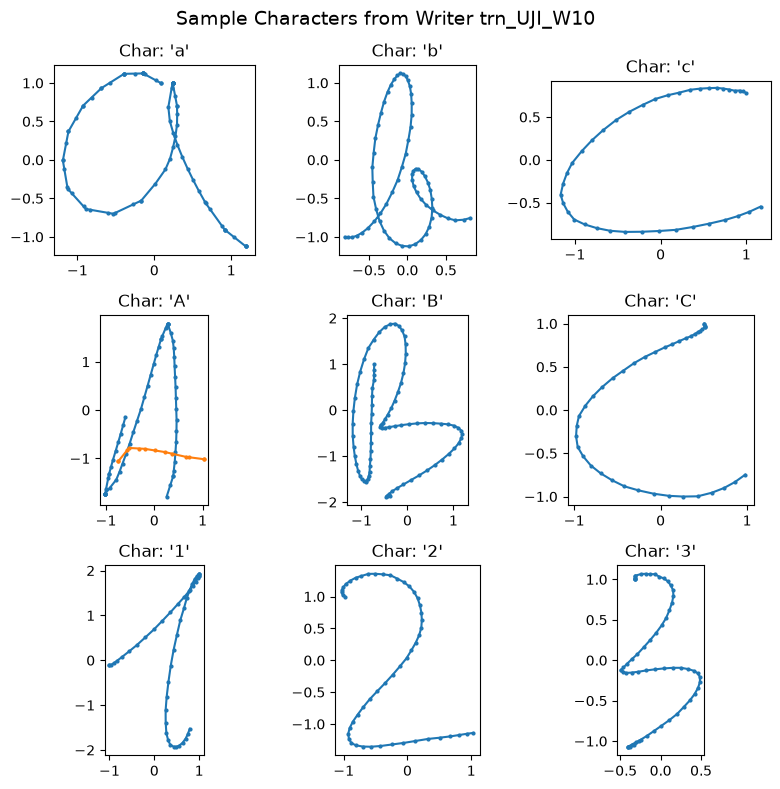

In [6]:
# Plot from delta_data
characters = ['a', 'b', 'c', 'A', 'B', 'C', '1', '2', '3']
writer = "trn_UJI_W10"

fig, axes = plt.subplots(3, 3, figsize=(8, 8))

for ax, char in zip(axes.flat, characters):
    # Get the flat trajectory from delta_data
    trajectory = train_data[writer][char][0]

    # Reconstruct strokes from (dx, dy, pen_state)
    strokes = deltas_to_strokes(trajectory)
    print(f"Character '{char}' has {len(strokes)} strokes after reconstruction.")

    for stroke in strokes:
        xs = [p[0] for p in stroke]
        ys = [p[1] for p in stroke]
        ax.plot(xs, ys, "-o", markersize=2)

    ax.set_aspect("equal")
    ax.set_title(f"Char: '{char}'")

plt.suptitle(f"Sample Characters from Writer {writer}", fontsize=14)
plt.tight_layout()
plt.show()

In [7]:
# # Keep originals and add small rotations to training data only.
# ROTATION_ANGLES = (-2.0, 2.0)

# def augment_training_data(data_split, angles):
#     augmented_data = {}

#     for writer_id, characters in data_split.items():
#         augmented_data[writer_id] = {}

#         for char, repetitions in characters.items():
#             augmented_repetitions = []

#             for repetition in repetitions:
#                 trajectory = np.array(
#                     repetition, dtype=np.float32, copy=True
#                 )
#                 augmented_repetitions.append(trajectory)

#                 for angle in angles:
#                     radians = np.deg2rad(angle)
#                     cos_angle = np.cos(radians)
#                     sin_angle = np.sin(radians)

#                     rotation = np.array([
#                         [cos_angle, -sin_angle],
#                         [sin_angle, cos_angle],
#                     ], dtype=np.float32)

#                     rotated = trajectory.copy()

#                     # Rotate movement vectors; preserve pen states.
#                     rotated[:, :2] = trajectory[:, :2] @ rotation.T
#                     augmented_repetitions.append(rotated)

#             augmented_data[writer_id][char] = augmented_repetitions

#     return augmented_data


# # Start from the original samples to avoid accumulating copies on reruns.
# original_train_data = {
#     writer_id: characters
#     for writer_id, characters in delta_data.items()
#     if writer_id.startswith("trn_")
# }

# train_data = augment_training_data(
#     original_train_data, ROTATION_ANGLES
# )

# print(
#     f"Training samples: {count_samples(original_train_data)} originals"
#     f" -> {count_samples(train_data)} after augmentation"
# )
# print(f"Validation samples: {count_samples(val_data)}")
# print(f"Test samples: {count_samples(test_data)}")

In [8]:
# 1. Collect all unique characters and give each one a unique number (0, 1, 2, ...)
all_chars = []
for writer_id in delta_data:
    for char in delta_data[writer_id]:
        if char not in all_chars:
            all_chars.append(char)

#char_to_id = {char: i for i , char in enumerate(all_chars)}
char_to_id = {}
for i in range(len(all_chars)):
    char_to_id[all_chars[i]] = i

num_chars = len(all_chars)

print(f"Total unique characters: {num_chars}")

# 2. Build dataset lists with the shared char_to_id
def build_dataset_lists(data_split):
    c_list = []
    X_list = []
    y_list = []

    for writer_id in data_split:
        for char in data_split[writer_id]:
            c_id = char_to_id[char]  # Uses the shared character ID

            for rep in data_split[writer_id][char]:
                traj = np.array(rep, dtype=np.float32)
                len_traj = len(traj)
                traj = np.array(rep, dtype=np.float32)

                start = np.array([[0.0, 0.0, 1.0]], dtype=np.float32)
                inp = np.concatenate([start, traj[:-1]], axis=0)
                tgt = traj
                c_list.append(c_id)
                X_list.append(inp)
                y_list.append(tgt)

    return c_list, X_list, y_list


c_train, X_train, y_train = build_dataset_lists(train_data)
c_val,   X_val,   y_val   = build_dataset_lists(val_data)
c_test,  X_test,  y_test  = build_dataset_lists(test_data)

Total unique characters: 97


In [9]:
# 1. Find the maximum sequence length across all sets
max_len = 0
for seq in X_train + X_val + X_test:
    if len(seq) > max_len:
        max_len = len(seq)

print("Maximum sequence length:", max_len)


# 2. Simple padding function
def pad_data(c_list, X_list, y_list, max_len):
    total_samples = len(X_list)

    # Create empty arrays filled with zeros
    X_padded = np.zeros((total_samples, max_len, 3), dtype=np.float32)
    y_padded = np.zeros((total_samples, max_len, 3), dtype=np.float32)
    mask = np.zeros((total_samples, max_len), dtype=bool)

    # Fill in the real data
    for i in range(total_samples):
        seq_len = len(X_list[i])

        # Copy original points
        X_padded[i, :seq_len, :] = X_list[i]
        y_padded[i, :seq_len, :] = y_list[i]

        # True for real points, False for padded zeros
        mask[i, :seq_len] = True

    c_array = np.array(c_list, dtype=np.int64)

    return c_array, X_padded, y_padded, mask


# 3. Apply padding to Train, Val, and Test
c_train_pad, X_train_pad, y_train_pad, mask_train = pad_data(c_train, X_train, y_train, max_len)
c_val_pad,   X_val_pad,   y_val_pad,   mask_val   = pad_data(c_val,   X_val,   y_val,   max_len)
c_test_pad,  X_test_pad,  y_test_pad,  mask_test  = pad_data(c_test,  X_test,  y_test,  max_len)

print("Padded X_train shape:", X_train_pad.shape)
print("Mask train shape:    ", mask_train.shape)

Maximum sequence length: 97
Padded X_train shape: (7760, 97, 3)
Mask train shape:     (7760, 97)


In [10]:
# Convert to PyTorch Datasets
train_dataset = TensorDataset(
    torch.tensor(c_train_pad),
    torch.tensor(X_train_pad),
    torch.tensor(y_train_pad),
    torch.tensor(mask_train)
)

val_dataset = TensorDataset(
    torch.tensor(c_val_pad),
    torch.tensor(X_val_pad),
    torch.tensor(y_val_pad),
    torch.tensor(mask_val)
)

test_dataset = TensorDataset(
    torch.tensor(c_test_pad),
    torch.tensor(X_test_pad),
    torch.tensor(y_test_pad),
    torch.tensor(mask_test)
)
train_loader = DataLoader(train_dataset)
val_loader   = DataLoader(val_dataset)
test_loader  = DataLoader(test_dataset)

In [11]:
# ==============================================================================
# CHANGE 1: LSTM with MDN coordinate head (instead of one deterministic dx,dy)
# The REQUIRED generated output is STILL (dx, dy, pen_state).
# Only the internal coordinate prediction is probabilistic.
# ==============================================================================

class HandwritingLSTM(nn.Module):
    def __init__(self, num_chars, hidden_size=128, num_layers=3,
                 embedding_dim=32, dropout_p=0.1, n_mixtures=5):
        super().__init__()
        self.n_mixtures = n_mixtures
        self.char_embedding = nn.Embedding(num_chars, embedding_dim)
        self.emb_dropout = nn.Dropout(dropout_p * 0.1)
        self.lstm = nn.LSTM(
            input_size=3 + embedding_dim,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout_p if num_layers > 1 else 0.0,
        )
        self.out_dropout = nn.Dropout(dropout_p)

        # CHANGE: Each of K Gaussian components predicts:
        # [mixture_logit, mean_dx, mean_dy, log_std_dx, log_std_dy].
        # One valid (dx,dy) is selected/sampled during generation.
        self.xy_head = nn.Linear(hidden_size, n_mixtures * 5)

        # UNCHANGED: 3 pen states: 0=down, 1=up, 2=end.
        self.pen_head = nn.Linear(hidden_size, 3)

    def forward(self, x, c, hidden=None):
        batch_size, seq_len, _ = x.shape
        char_emb = self.emb_dropout(self.char_embedding(c.long()))
        char_emb = char_emb.unsqueeze(1).expand(-1, seq_len, -1)
        lstm_input = torch.cat([x, char_emb], dim=-1)
        output, hidden = self.lstm(lstm_input, hidden)
        output = self.out_dropout(output)

        mdn_params = self.xy_head(output).reshape(
            batch_size, seq_len, self.n_mixtures, 5
        )
        pen_logits = self.pen_head(output)
        return mdn_params, pen_logits, hidden


In [12]:
# ==============================================================================
# CHANGE 2: Compute pen-state class weights once, from TRAINING data only.
# First/pen-up displacement divisors are not used in MDN NLL; their old
# values were greatly downweighting long jumps in the coordinate objective.
# ==============================================================================

train_pen = train_dataset.tensors[2][:, :, 2].long()
train_mask = train_dataset.tensors[3].bool()
class_counts = torch.bincount(train_pen[train_mask], minlength=3).float()
assert (class_counts > 0).all(), "A pen-state class is absent from training data."

# CHANGE: Keep these weights on CPU here (the device is defined later).
# They are transferred to the logits' device when used in the loss.
pen_class_weights = (class_counts.max() / class_counts).sqrt()
print("Pen-state counts:", class_counts.tolist())
print("Pen-state weights:", pen_class_weights.tolist())


Pen-state counts: [450018.0, 12352.0, 7760.0]
Pen-state weights: [1.0, 6.035959243774414, 7.615248680114746]


In [13]:
# ==============================================================================
# CHANGE 3: Gaussian Mixture negative log-likelihood instead of coordinate MSE.
# Pen-state cross entropy is unchanged; dx/dy are still the actual targets.
# ==============================================================================

import math
import torch.nn.functional as F

def compute_loss_and_metrics(predictions, targets, mask, coord_std, pen_weight):
    mdn_params, pen_logits, _ = predictions
    xy_target = targets[:, :, :2]                # [B, T, 2]
    pen_target = targets[:, :, 2].long()         # [B, T]
    valid = mask.bool()
    n_valid = valid.sum().clamp(min=1)

    # Each Gaussian component: mixture logit, 2 means, 2 log-standard deviations.
    mixture_logits = mdn_params[..., 0]         # [B, T, K]
    means = mdn_params[..., 1:3]                 # [B, T, K, 2]
    log_stds = mdn_params[..., 3:5].clamp(-5, 2)

    # Log density of the observed (dx,dy) under every Gaussian component.
    z = (xy_target.unsqueeze(2) - means) / log_stds.exp()
    gaussian_log_density = (
        -0.5 * z.square().sum(dim=-1)
        - log_stds.sum(dim=-1)
        - math.log(2 * math.pi)
    )
    log_mix_probs = F.log_softmax(mixture_logits, dim=-1)

    # CHANGE: likelihood sums the probability of all plausible movements,
    # rather than forcing the network to output a single averaged movement.
    xy_nll = -torch.logsumexp(log_mix_probs + gaussian_log_density, dim=-1)

    # State 2 is an end marker (dx,dy=0), not a physical movement.
    coord_mask = valid & (pen_target != 2)
    coord_loss = (
        (xy_nll * coord_mask.float()).sum()
        / coord_mask.sum().clamp(min=1)
    )

    # UNCHANGED objective: 3-state weighted cross entropy for pen state.
    safe_targets = pen_target.masked_fill(~valid, 0)
    pen_ce = F.cross_entropy(
        pen_logits.transpose(1, 2),
        safe_targets,
        weight=pen_class_weights.to(pen_logits.device),
        reduction="none",
    )
    pen_loss = (pen_ce * valid.float()).sum() / n_valid

    # NOTE: NLL and total loss may be negative; that is valid for densities.
    loss = coord_loss + pen_weight * pen_loss
    return loss, coord_loss, pen_loss


In [14]:

# ==============================================================================
# 3. TRAINING CONFIGURATION & INITIALIZATION
# ==============================================================================


# Model hyperparameters
LSTM_HIDDEN = 128
LSTM_LAYERS = 5
EMBEDDING_DIM = 32

# Training hyperparameters
BATCH_SIZE = 64
PATIENCE = 30
MIN_IMPROVEMENT = 1e-5
PRINT_EVERY = 1

# Pen-state loss weight
PEN_WEIGHT = 0.0263


torch.manual_seed(42)
np.random.seed(42)

# CPU selected because the installed PyTorch CUDA build
# was incompatible with your NVIDIA MX230
device = torch.device("cpu")

print("Using device:", device)

# ----------------------------------------------------
# A. DataLoaders
# ----------------------------------------------------

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

# ----------------------------------------------------
# B. Calculate coordinate standard deviations
# ----------------------------------------------------

train_targets = train_dataset.tensors[2]
train_masks = train_dataset.tensors[3].bool()

valid_xy = train_targets[:, :, :2][train_masks]

coord_std = valid_xy.std(
    dim=0, correction=0
).clamp(min=1e-6).to(device)

print("Coordinate standard deviations:", coord_std)

# ----------------------------------------------------
# C. Initialize the LSTM
# ----------------------------------------------------

model = HandwritingLSTM(
    num_chars=num_chars,
    hidden_size=LSTM_HIDDEN,
    num_layers=LSTM_LAYERS,
    embedding_dim=EMBEDDING_DIM
).to(device)

print(model)

n_parameters = sum(
    p.numel() for p in model.parameters()
)

print(f"\nLearnable parameters: {n_parameters:,}")

# ----------------------------------------------------
# E. Initialize training history
# ----------------------------------------------------

metrics = [
    "loss",
    "coord_loss",
    "pen_loss",
]

history = {}

for metric in metrics:
    history["train_" + metric] = []
    history["val_" + metric] = []

# ----------------------------------------------------
# F. Initialize early stopping and checkpoints
# ----------------------------------------------------

best_val_loss = float("inf")
best_state = copy.deepcopy(model.state_dict())
best_epoch = -1

stage_boundary_epoch = None


Using device: cpu
Coordinate standard deviations: tensor([0.1291, 0.1671])
HandwritingLSTM(
  (char_embedding): Embedding(97, 32)
  (emb_dropout): Dropout(p=0.010000000000000002, inplace=False)
  (lstm): LSTM(35, 128, num_layers=5, batch_first=True, dropout=0.1)
  (out_dropout): Dropout(p=0.1, inplace=False)
  (xy_head): Linear(in_features=128, out_features=25, bias=True)
  (pen_head): Linear(in_features=128, out_features=3, bias=True)
)

Learnable parameters: 619,580


In [15]:
# ==============================================================================
# 4. TRAINING LOOP
# ==============================================================================

def run_epoch(loader, optimizer=None):

    training = optimizer is not None
    model.train(training)

    totals = {
        "loss": 0.0,
        "coord_loss": 0.0,
        "pen_loss": 0.0,
        "pen_acc": 0.0
    }

    total_valid_points = 0
    total_true_up = 0
    total_correct_up = 0
    raw_coordinate_sse = 0.0
    raw_coordinate_n = 0

    with torch.set_grad_enabled(training):

        for batch_c, batch_X, batch_y, batch_mask in loader:
            # Move data to device
            batch_c = batch_c.to(device)
            batch_X = batch_X.to(device)
            batch_y = batch_y.to(device)
            batch_mask = batch_mask.to(device)

            # ----------------------------------------------------
            # A. Forward pass
            # ----------------------------------------------------

            if training:
                optimizer.zero_grad()

            predictions = model(batch_X, batch_c)

            # ----------------------------------------------------
            # B. Calculate loss and metrics
            # ----------------------------------------------------

            loss, coord_l, pen_l = (
                compute_loss_and_metrics(
                    predictions,
                    batch_y,
                    batch_mask,
                    coord_std,
                    PEN_WEIGHT
                )
            )

            # ----------------------------------------------------
            # C. Backpropagation (training only)
            # ----------------------------------------------------

            if training:

                loss.backward()

                torch.nn.utils.clip_grad_norm_(
                    model.parameters(),
                    max_norm=1
                )

                optimizer.step()

            # ----------------------------------------------------
            # D. Accumulate loss and accuracy
            # ----------------------------------------------------

            n = batch_mask.sum().item()
            total_valid_points += n

            totals["loss"] += loss.item() * n
            totals["coord_loss"] += coord_l.item() * n
            # CHANGE: Actually log pen loss (previous code left it at zero).
            totals["pen_loss"] += pen_l.item() * n

            # ----------------------------------------------------
            # E. Calculate pen-up recall counts
            # ----------------------------------------------------

            with torch.no_grad():

                # CHANGE: Diagnostic raw coordinate error in normalized dx/dy
                # units (NOT the MDN NLL used for training).
                mdn = predictions[0]
                probs = torch.softmax(mdn[..., 0], dim=-1)
                predicted_mean = (probs.unsqueeze(-1) * mdn[..., 1:3]).sum(dim=2)
                raw_mse = ((predicted_mean - batch_y[..., :2]) ** 2).mean(dim=-1)
                valid_xy = batch_mask.bool() & (batch_y[..., 2] != 2)
                raw_coordinate_sse += raw_mse[valid_xy].sum().item()
                raw_coordinate_n += valid_xy.sum().item()

                # Predicted class indices: shape [batch_size, seq_len]
                pen_preds = predictions[1].argmax(dim=-1)

                # Class 1 is pen-up
                predicted_up = (pen_preds == 1)

                actual_up = (
                    (batch_y[:, :, 2].long() == 1)
                    & batch_mask.bool()
                )

                total_true_up += actual_up.sum().item()

                total_correct_up += (
                    predicted_up & actual_up
                ).sum().item()

    # ----------------------------------------------------
    # F. Final epoch metrics
    # ----------------------------------------------------

    results = {
        key: value / total_valid_points
        for key, value in totals.items()
    }

    # CHANGE: MDN NLL is not an MSE and may be negative; sqrt(NLL) is invalid.
    # This RMSE uses the predicted mixture mean for diagnostic comparison.
    results["coord_rmse"] = np.sqrt(
        raw_coordinate_sse / max(raw_coordinate_n, 1)
    )

    results["pen_up_recall"] = (
        total_correct_up / total_true_up
        if total_true_up > 0
        else float("nan")
    )

    return results


# ==============================================================================
# MAIN TRAINING PROCESS: TWO STAGES
# ==============================================================================
val_loss=0


# New optimizer, retaining trained model weights
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=10,        # Increased from 5 to 10
    min_lr=1e-5         # Prevent the LR from dropping below 1e-5mode="min", factor=0.5, patience=5
)


epochs_without_improvement = 0
max_epochs = 1000

try:

    for stage_epoch in range(max_epochs):

        # ----------------------------------------------------
        # A. Training
        # ----------------------------------------------------

        train_results = run_epoch(
            train_loader,
            optimizer=optimizer
        )

        # ----------------------------------------------------
        # B. Validation
        # ----------------------------------------------------

        val_results = run_epoch(
            val_loader,
            optimizer=None
        )
        val_loss = val_results["loss"]
        scheduler.step(val_loss)
        # ----------------------------------------------------
        # C. Record learning curves
        # ----------------------------------------------------

        for metric in metrics:

            history["train_" + metric].append(
                train_results[metric]
            )

            history["val_" + metric].append(
                val_results[metric]
            )

        current_epoch = len(history["train_loss"])

        # ----------------------------------------------------
        # D. Best checkpoint and early stopping
        # ----------------------------------------------------

        val_loss = val_results["loss"]

        if val_loss < best_val_loss - MIN_IMPROVEMENT:

            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = current_epoch - 1

            epochs_without_improvement = 0

        else:
            epochs_without_improvement += 1

        # ----------------------------------------------------
        # E. Print training progress
        # ----------------------------------------------------

        if (stage_epoch + 1) % PRINT_EVERY == 0:

            print(
                f"Epoch {current_epoch:3d} | "
                f"Train Loss: {train_results['loss']:.5f} | "
                f"Val Loss: {val_results['loss']:.5f} | "
                f"Val XY NLL: {val_results['coord_loss']:.5f} | "
                f"Val XY RMSE: {val_results['coord_rmse']:.5f} | "
                f"Val Pen CE: {val_results['pen_loss']:.5f} | "
            )

        # ----------------------------------------------------
        # F. Early stopping
        # ----------------------------------------------------

        if epochs_without_improvement >= PATIENCE:

            print(
                f"\nEarly stopping at epoch {current_epoch}."
            )

            break
except KeyboardInterrupt:
    print("\nTraining interrupted by user.")

# ==============================================================================
# RESTORE BEST MODEL
# ==============================================================================

model.load_state_dict(best_state)

print(
    f"\nBest Epoch: {best_epoch + 1} | "
    f"Best Validation Loss: {best_val_loss:.5f}"
)


/media/ahmed-nabil/university/machine learninig/labs/lab2/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:484: UserWarning: Found GPU0 NVIDIA GeForce MX230 which is of compute capability (CC) 6.1.
The following list shows the CCs this version of PyTorch was built for and the hardware CCs it supports:
- 7.5 which supports hardware CC >=7.5,<8.0
- 8.0 which supports hardware CC >=8.0,<9.0 except {8.7}
- 8.6 which supports hardware CC >=8.6,<9.0 except {8.7}
- 9.0 which supports hardware CC >=9.0,<10.0
- 10.0 which supports hardware CC >=10.0,<11.0 except {10.1}
- 12.0 which supports hardware CC >=12.0,<13.0
Your installed torch==2.14.1+cu130 does not include kernels for this GPU. Reinstall the same version against a CUDA build that does, e.g.:
  For CUDA 12.6 use pip install torch==2.14.1 --index-url https://download.pytorch.org/whl/cu126
  _warn_unsupported_code(d, device_cc, code_ccs)
/media/ahmed-nabil/university/machine learninig/labs/lab2/.venv/lib/python3.12/site-packages

Epoch   1 | Train Loss: -1.19330 | Val Loss: -1.99087 | Val XY NLL: -2.01108 | Val XY RMSE: 0.15215 | Val Pen CE: 0.76856 | 
Epoch   2 | Train Loss: -2.01229 | Val Loss: -2.17307 | Val XY NLL: -2.19272 | Val XY RMSE: 0.15120 | Val Pen CE: 0.74707 | 
Epoch   3 | Train Loss: -2.14370 | Val Loss: -2.22942 | Val XY NLL: -2.24878 | Val XY RMSE: 0.15074 | Val Pen CE: 0.73600 | 
Epoch   4 | Train Loss: -2.22948 | Val Loss: -2.32115 | Val XY NLL: -2.34026 | Val XY RMSE: 0.15023 | Val Pen CE: 0.72629 | 
Epoch   5 | Train Loss: -2.31014 | Val Loss: -2.37589 | Val XY NLL: -2.39456 | Val XY RMSE: 0.14894 | Val Pen CE: 0.70980 | 
Epoch   6 | Train Loss: -2.38727 | Val Loss: -2.46837 | Val XY NLL: -2.48653 | Val XY RMSE: 0.14598 | Val Pen CE: 0.69042 | 
Epoch   7 | Train Loss: -2.59864 | Val Loss: -2.88266 | Val XY NLL: -2.90016 | Val XY RMSE: 0.13760 | Val Pen CE: 0.66544 | 
Epoch   8 | Train Loss: -2.90966 | Val Loss: -3.25275 | Val XY NLL: -3.26977 | Val XY RMSE: 0.13040 | Val Pen CE: 0.64685 | 


### Stage 2: fine-tuning
Run this optional stage after the main training cell. It continues from the best weights with a learning rate at most `1e-5` and at least 10 times lower than the final Stage 1 rate. It trains for up to 100 epochs with early stopping, extends `history`, and restores the best model across both stages. Keep the model initialization cell unexecuted when continuing an existing training session.


In [ ]:
# Stage 2: fine-tune the best model from Stage 1.
# Run after the main training cell, without rerunning model initialization.
model.load_state_dict(best_state)
stage_boundary_epoch = len(history["train_loss"])
stage1_best_val_loss = best_val_loss

# Reduce the final Stage 1 learning rate by at least 10x.
previous_lr = min(group["lr"] for group in optimizer.param_groups)
FT_LR = min(1e-5, previous_lr * 0.1)
FT_MAX_EPOCHS = 100
FT_PATIENCE = 15
FT_MIN_IMPROVEMENT = MIN_IMPROVEMENT

# Fine-tune all layers, keeping the same loss and pen-state weight.
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=FT_LR,
    weight_decay=1e-4,
)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=5,
    min_lr=FT_LR * 0.01,
    threshold=FT_MIN_IMPROVEMENT,
    threshold_mode="abs",
)

epochs_without_improvement = 0
# Track meaningful improvements separately from the best checkpoint.
stopping_best_loss = best_val_loss
print(f"Fine-tuning from epoch {best_epoch + 1}, LR={FT_LR:.2e}")

try:
    for ft_epoch in range(FT_MAX_EPOCHS):
        train_results = run_epoch(train_loader, optimizer=optimizer)
        val_results = run_epoch(val_loader)
        val_loss = val_results["loss"]
        if not np.isfinite(val_loss):
            raise RuntimeError("Fine-tuning validation loss is not finite.")
        scheduler.step(val_loss)

        for metric in metrics:
            history["train_" + metric].append(train_results[metric])
            history["val_" + metric].append(val_results[metric])

        current_epoch = len(history["train_loss"])

        # Keep the lowest validation loss across BOTH training stages.
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = current_epoch - 1

        if val_loss < stopping_best_loss - FT_MIN_IMPROVEMENT:
            stopping_best_loss = val_loss
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if (ft_epoch + 1) % PRINT_EVERY == 0:
            print(
                f"Fine-tune {ft_epoch + 1:3d} | Epoch {current_epoch:3d} | "
                f"Train Loss: {train_results['loss']:.5f} | "
                f"Val Loss: {val_loss:.5f} | "
                f"Val XY NLL: {val_results['coord_loss']:.5f} | "
                f"Val Pen CE: {val_results['pen_loss']:.5f} | "
                f"LR: {optimizer.param_groups[0]['lr']:.2e}"
            )

        if epochs_without_improvement >= FT_PATIENCE:
            print(f"Fine-tuning early stopping at epoch {current_epoch}.")
            break
except KeyboardInterrupt:
    print("Fine-tuning interrupted; restoring the best model.")
finally:
    model.load_state_dict(best_state)
    model.eval()

print(
    f"Stage 1 best validation loss: {stage1_best_val_loss:.5f}\n"
    f"Best validation loss after fine-tuning: {best_val_loss:.5f}\n"
    f"Best epoch overall: {best_epoch + 1}"
)


In [16]:
model.load_state_dict(best_state)

print(
    f"\nBest Epoch: {best_epoch + 1} | "
    f"Best Validation Loss: {best_val_loss:.5f}"
)



Best Epoch: 147 | Best Validation Loss: -6.17992


### Load the latest saved model (skip training)
Run the imports cell and the cell defining `HandwritingLSTM`, then run the cell below. It selects the most recently modified `handwriting_lstm*.pt` checkpoint and restores the model for inference. You can skip all training cells.

To plot generated characters, also run the `deltas_to_strokes` definition, then the `generate_trajectory` definition and the sample-character plotting cell below.


In [17]:
# # Load the most recently saved checkpoint without retraining.
# checkpoint_paths = list(Path(".").glob("handwriting_lstm*.pt"))
# if not checkpoint_paths:
#     raise FileNotFoundError("No handwriting_lstm*.pt checkpoints found in the current directory.")

# checkpoint_path = max(checkpoint_paths, key=lambda path: path.stat().st_mtime_ns)

# # Use CPU, matching this notebook's training configuration.
# device = torch.device("cpu")
# checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=True)

# model = HandwritingLSTM(**checkpoint["model_config"]).to(device)
# model.load_state_dict(checkpoint["model_state_dict"])
# model.eval()

# char_to_id = checkpoint["char_to_id"]
# num_chars = checkpoint["model_config"]["num_chars"]
# coord_std = checkpoint["coord_std"].to(device)

# print(f"Loaded: {checkpoint_path.name}")
# print(f"Saved best epoch: {checkpoint['best_epoch']}")
# print(f"Available characters: {len(char_to_id)}")


In [20]:
@torch.inference_mode()
def generate_trajectory(model, char, char_to_id, max_steps=97):
    """Return an (N, 3) NumPy array of (dx, dy, pen_state).

    Pen states: 0 = draw, 1 = pen up, 2 = end of character.
    """
    if char not in char_to_id:
        raise ValueError(f"Unknown character: {char!r}")
    if max_steps < 1:
        raise ValueError("max_steps must be positive.")

    parameter = next(model.parameters())
    c = torch.tensor(
        [char_to_id[char]], dtype=torch.long, device=parameter.device
    )

    # Same start token used during training.
    x = parameter.new_tensor([[[0.0, 0.0, 1.0]]])
    hidden = None
    trajectory = []

    was_training = model.training
    model.eval()

    try:
        for _ in range(max_steps):
            mdn_params, pen_logits, hidden = model(x, c, hidden)

            # Each Gaussian: [logit, mean_dx, mean_dy, log_std_dx, log_std_dy].
            mdn = mdn_params[0, -1]         # (n_mixtures, 5)
            component = mdn[:, 0].argmax()
            xy = mdn[component, 1:3]       # (2,)

            pen_state = pen_logits[0, -1].argmax()
            step = torch.cat([
                xy,
                pen_state.to(dtype=xy.dtype).reshape(1),
            ])                            # (3,)

            trajectory.append(step)

            if pen_state.item() == 2:
                break

            # Feed the predicted point into the next step.
            x = step.reshape(1, 1, 3)

    finally:
        model.train(was_training)

    return torch.stack(trajectory).cpu().numpy()

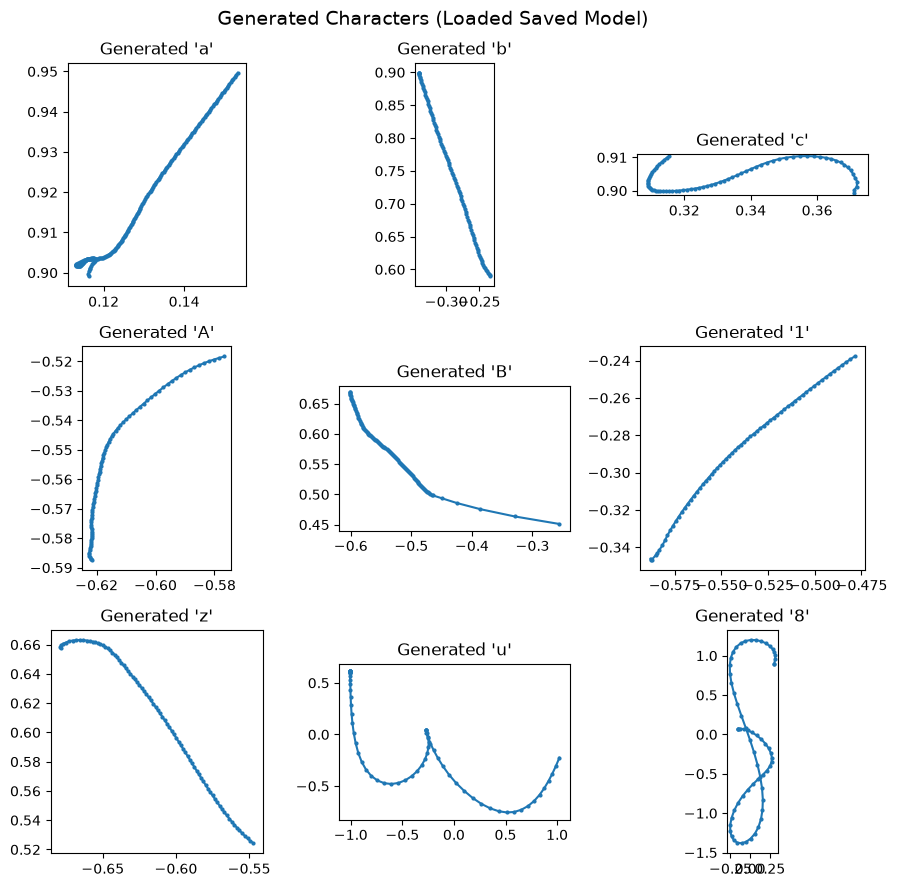

In [23]:
# ==============================================================================
# VISUALIZE: GENERATE SAMPLE CHARACTERS WITH BEST MODEL
# ==============================================================================

sample_chars = ['a', 'b', 'c', 'A', 'B', '1', 'z', 'u', '8']
fig, axes = plt.subplots(3, 3, figsize=(9, 9))

for ax, char in zip(axes.flat, sample_chars):
    if char in char_to_id:
        gen_trajectory = generate_trajectory(model, char, char_to_id, max_steps=200)
        strokes = deltas_to_strokes(gen_trajectory)
        for stroke in strokes:
            xs = [p[0] for p in stroke]
            ys = [p[1] for p in stroke]
            ax.plot(xs, ys, "-o", markersize=2)
        ax.set_aspect("equal")
        ax.set_title(f"Generated '{char}'")
    else:
        ax.axis("off")

plt.suptitle("Generated Characters (Loaded Saved Model)", fontsize=14)
plt.tight_layout()
plt.show()